Gap Aware Lag analysis(The complete Aug-2002–Jan-2026 monthly calendar, with the 13 low-coverage CHL months entered as NaN.)

In [1]:
# ================================================================
# GAP-AWARE LAG ANALYSIS
# ================================================================
#
# Study period:
#     August 2002 – January 2026
#
# Excel columns:
#     Month-Year
#     Niño 3.4
#     DMI
#     CHL (mg/m^3)
#     SST (°C)
#
# Important:
#     Months with CHL coverage <20% remain in the calendar,
#     but their CHL value is NaN.
#
# Main correction:
#     Lag and autocorrelation are calculated using ACTUAL
#     CALENDAR MONTHS, not row positions.
#
# Lag definition:
#     Predictor(t-k) -> CHL(t)
#
# Primary analysis:
#     Calendar-aware lagged Pearson correlation
#     + effective sample size correction
#     + Fisher 95% CI
#     + Benjamini-Hochberg FDR correction
#
# Robustness analysis:
#     Calendar-aware AR(1) prewhitening
#     + lag scan
#     + FDR correction
#
# ================================================================


# ================================================================
# 0. IMPORT LIBRARIES
# ================================================================

import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests
import os


# ================================================================
# 1. FILE PATH
# ================================================================

input_file = "Anomalized_detrended_SST&CHL.xlsx"
output_file = "Gap_Aware_Lag_Analysis.xlsx"


# ================================================================
# 2. READ DATA
# ================================================================

df = pd.read_excel(input_file)

print("\nOriginal data:")
print(df.head())

print("\nOriginal Excel columns:")
print(df.columns.tolist())


# ================================================================
# 3. CLEAN COLUMN NAMES
# ================================================================
#
# Strip accidental leading/trailing spaces from Excel headers.
#
# ================================================================

df.columns = df.columns.astype(str).str.strip()

print("\nCleaned Excel columns:")
print(df.columns.tolist())


# ================================================================
# 4. RENAME COLUMNS USING YOUR EXACT COLUMN NAMES
# ================================================================

column_mapping = {
    "Month-Year": "Date",
    "Niño 3.4": "Nino34",
    "DMI": "DMI",
    "CHL (mg/m^3)": "CHL",
    "SST (°C)": "SST"
}

df = df.rename(columns=column_mapping)


# ================================================================
# 5. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [
    "Date",
    "Nino34",
    "DMI",
    "CHL",
    "SST"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        "\nMissing required columns:\n"
        f"{missing_columns}\n\n"
        "Available columns are:\n"
        f"{df.columns.tolist()}\n\n"
        "Expected Excel headers are:\n"
        "Month-Year\n"
        "Niño 3.4\n"
        "DMI\n"
        "CHL (mg/m^3)\n"
        "SST (°C)"
    )


print("\n✓ All required columns detected.")


# ================================================================
# 6. KEEP ONLY REQUIRED VARIABLES
# ================================================================

df = df[required_columns].copy()


# ================================================================
# 7. CONVERT MONTH-YEAR TO DATETIME
# ================================================================

df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    format="%b-%Y",
    errors="coerce"
)

if df["Date"].isna().any():

    print("\nERROR: Some Month-Year values could not be converted.")

    print(
        df.loc[
            df["Date"].isna(),
            "Date"
        ]
    )

    raise ValueError(
        "\nCheck the Month-Year format.\n"
        "Expected format example: Aug-2002"
    )


# ================================================================
# 8. CONVERT NUMERIC VARIABLES
# ================================================================

numeric_columns = [
    "Nino34",
    "DMI",
    "CHL",
    "SST"
]

for col in numeric_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ================================================================
# 9. SORT CHRONOLOGICALLY
# ================================================================

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)


# ================================================================
# 10. CHECK DUPLICATE MONTHS
# ================================================================

if df["Date"].duplicated().any():

    duplicates = df[
        df["Date"].duplicated(
            keep=False
        )
    ]

    print("\nDuplicate dates found:")
    print(duplicates)

    raise ValueError(
        "\nDuplicate months exist in the dataset. "
        "Resolve them before continuing."
    )

else:

    print(
        "\n✓ No duplicate calendar months detected."
    )


# ================================================================
# 11. CREATE COMPLETE MONTHLY CALENDAR
# ================================================================

full_dates = pd.date_range(
    start="2002-08-01",
    end="2026-01-01",
    freq="MS"
)

expected_n_months = len(full_dates)

print(
    "\nExpected calendar months:",
    expected_n_months
)

print(
    "Months currently in Excel:",
    len(df)
)


# ================================================================
# 12. SET DATE AS INDEX
# ================================================================

df = df.set_index("Date")

df.index.name = "Date"


# ================================================================
# 13. REINDEX TO COMPLETE CALENDAR
# ================================================================

df = df.reindex(full_dates)

df.index.name = "Date"


# ================================================================
# 14. VERIFY CONTINUOUS CALENDAR
# ================================================================

if df.index.equals(full_dates):

    print(
        "\n✓ Complete monthly calendar confirmed."
    )

else:

    raise ValueError(
        "Calendar is not continuous."
    )


# ================================================================
# 15. BASIC DATA CHECK
# ================================================================

print("\n================================================")
print("DATASET CHECK")
print("================================================")

print("\nDataset beginning:")
print(df.head())

print("\nDataset ending:")
print(df.tail())

print("\nMissing values:")
print(
    df[
        [
            "Nino34",
            "DMI",
            "CHL",
            "SST"
        ]
    ].isna().sum()
)


# ================================================================
# 16. IDENTIFY MISSING CHL MONTHS
# ================================================================

missing_chl = df.index[
    df["CHL"].isna()
]

print(
    "\n================================================"
)

print(
    "MONTHS WITH CHL = NaN"
)

print(
    "================================================"
)

for date in missing_chl:

    print(
        date.strftime("%Y-%m")
    )


print(
    "\nNumber of missing CHL months:",
    len(missing_chl)
)


# ================================================================
# 17. IDENTIFY AVAILABLE CHL MONTHS
# ================================================================

available_chl = df.index[
    df["CHL"].notna()
]

print(
    "Available CHL months:",
    len(available_chl)
)


# ================================================================
# 18. CHECK OTHER VARIABLES DURING MISSING CHL MONTHS
# ================================================================

print(
    "\n================================================"
)

print(
    "OTHER VARIABLES DURING MISSING-CHL MONTHS"
)

print(
    "================================================"
)

if len(missing_chl) > 0:

    print(
        df.loc[
            df["CHL"].isna(),
            [
                "Nino34",
                "DMI",
                "CHL",
                "SST"
            ]
        ]
    )

else:

    print(
        "No missing CHL months."
    )


# ================================================================
# 19. CALENDAR-AWARE LAGGED PAIRS
# ================================================================
#
# Predictor(t-k) -> CHL(t)
#
# Example:
#
# lag = 3
#
# January predictor
#        ↓
# April CHL
#
# Actual calendar dates are used.
#
# A missing month is NOT treated as a consecutive observation.
#
# ================================================================

def calendar_lag_pairs(
    data,
    predictor,
    response,
    lag
):

    """
    Creates calendar-aware pairs:

        Predictor(t-lag) -> Response(t)

    using actual calendar months.

    Parameters
    ----------
    data : DataFrame
    predictor : str
    response : str
    lag : int

    Returns
    -------
    DataFrame
        Columns:
        X = predictor(t-lag)
        Y = response(t)
    """

    predictor_series = data[predictor].copy()

    response_series = data[response].copy()

    # ------------------------------------------------------------
    # Move predictor forward by 'lag' calendar months.
    #
    # This converts:
    #
    # predictor at t-lag
    #
    # into:
    #
    # predictor aligned with response at t.
    # ------------------------------------------------------------

    target_dates = (
        predictor_series.index
        + pd.DateOffset(months=lag)
    )

    predictor_shifted = pd.Series(
        predictor_series.values,
        index=target_dates,
        name="X"
    )

    response_series = response_series.rename("Y")

    # ------------------------------------------------------------
    # Align by actual calendar date
    # ------------------------------------------------------------

    pairs = pd.concat(
        [
            predictor_shifted,
            response_series
        ],
        axis=1,
        join="inner"
    )

    # ------------------------------------------------------------
    # Remove missing pairs
    # ------------------------------------------------------------

    pairs = pairs.dropna()

    return pairs


# ================================================================
# 20. CALENDAR-AWARE LAG-1 AUTOCORRELATION
# ================================================================
#
# Only TRUE consecutive calendar months are used.
#
# Example:
#
# Jan -> Feb = valid
# Feb -> Mar = valid
#
# May -> July = NOT valid for lag-1
# if June is missing.
#
# ================================================================

def consecutive_month_autocorrelation(
    series
):

    """
    Calculates lag-1 autocorrelation using only pairs
    separated by exactly one calendar month.
    """

    s = series.dropna()

    if len(s) < 3:

        return np.nan

    # ------------------------------------------------------------
    # Current observation
    # ------------------------------------------------------------

    current = pd.DataFrame({
        "current": s
    })

    # ------------------------------------------------------------
    # Previous observation
    #
    # Move previous observation forward by exactly one month.
    # ------------------------------------------------------------

    previous = pd.DataFrame({
        "previous": s
    })

    previous.index = (
        previous.index
        + pd.DateOffset(months=1)
    )

    # ------------------------------------------------------------
    # Join only true consecutive calendar months
    # ------------------------------------------------------------

    paired = current.join(
        previous,
        how="inner"
    )

    if len(paired) < 3:

        return np.nan

    r1 = paired["current"].corr(
        paired["previous"]
    )

    return r1


# ================================================================
# 21. EFFECTIVE SAMPLE SIZE
# ================================================================
#
# Approximation:
#
# Neff = N(1-r1x*r1y)/(1+r1x*r1y)
#
# ================================================================

def effective_sample_size(
    n,
    r1_x,
    r1_y
):

    if (
        pd.isna(r1_x)
        or
        pd.isna(r1_y)
    ):

        return float(n)

    product = r1_x * r1_y

    # If product is negative, retain N
    if product < 0:

        return float(n)

    neff = (
        n
        *
        (1 - product)
        /
        (1 + product)
    )

    # Avoid impossible values

    neff = max(
        3.0,
        min(
            float(n),
            neff
        )
    )

    return neff


# ================================================================
# 22. CORRELATION STATISTICS
# ================================================================

def correlation_statistics(
    x,
    y,
    neff
):

    """
    Calculates:

        Pearson r
        ordinary p
        Neff-corrected p
        95% Fisher confidence interval
    """

    r, ordinary_p = stats.pearsonr(
        x,
        y
    )

    # Avoid numerical problems near +/-1

    r = np.clip(
        r,
        -0.999999,
        0.999999
    )

    # ------------------------------------------------------------
    # Corrected t-statistic
    # ------------------------------------------------------------

    t_value = (
        r
        *
        np.sqrt(
            (
                neff - 2
            )
            /
            (
                1 - r**2
            )
        )
    )

    corrected_p = (
        2
        *
        stats.t.sf(
            abs(t_value),
            df=neff - 2
        )
    )

    # ------------------------------------------------------------
    # Fisher 95% confidence interval
    # ------------------------------------------------------------

    z = np.arctanh(r)

    se_z = (
        1
        /
        np.sqrt(
            max(
                neff - 3,
                1
            )
        )
    )

    z_critical = stats.norm.ppf(
        0.975
    )

    z_low = (
        z
        -
        z_critical
        *
        se_z
    )

    z_high = (
        z
        +
        z_critical
        *
        se_z
    )

    ci_low = np.tanh(
        z_low
    )

    ci_high = np.tanh(
        z_high
    )

    return {
        "r": r,
        "ordinary_p": ordinary_p,
        "corrected_p": corrected_p,
        "CI95_low": ci_low,
        "CI95_high": ci_high
    }


# ================================================================
# 23. COMPLETE GAP-AWARE LAG SCAN
# ================================================================

def lag_scan(
    data,
    predictor,
    response="CHL",
    max_lag=12
):

    results = []

    # ------------------------------------------------------------
    # Calendar-aware lag-1 autocorrelation
    # ------------------------------------------------------------

    r1_x = consecutive_month_autocorrelation(
        data[predictor]
    )

    r1_y = consecutive_month_autocorrelation(
        data[response]
    )

    print("\n")
    print(
        "=================================================="
    )

    print(
        f"{predictor} -> {response}"
    )

    print(
        "=================================================="
    )

    print(
        f"Calendar-aware r1 ({predictor}) = "
        f"{r1_x:.4f}"
    )

    print(
        f"Calendar-aware r1 ({response}) = "
        f"{r1_y:.4f}"
    )

    # ------------------------------------------------------------
    # LAG 0–12
    # ------------------------------------------------------------

    for lag in range(
        max_lag + 1
    ):

        pairs = calendar_lag_pairs(
            data,
            predictor,
            response,
            lag
        )

        n = len(pairs)

        # --------------------------------------------------------
        # Too few observations
        # --------------------------------------------------------

        if n < 5:

            results.append({
                "Predictor": predictor,
                "Response": response,
                "Lag_months": lag,
                "N": n,
                "Neff": np.nan,
                "r": np.nan,
                "ordinary_p": np.nan,
                "corrected_p": np.nan,
                "CI95_low": np.nan,
                "CI95_high": np.nan
            })

            continue

        # --------------------------------------------------------
        # Effective sample size
        # --------------------------------------------------------

        neff = effective_sample_size(
            n,
            r1_x,
            r1_y
        )

        # --------------------------------------------------------
        # Correlation statistics
        # --------------------------------------------------------

        result = correlation_statistics(
            pairs["X"].values,
            pairs["Y"].values,
            neff
        )

        results.append({
            "Predictor": predictor,
            "Response": response,
            "Lag_months": lag,
            "N": n,
            "Neff": neff,
            "r": result["r"],
            "ordinary_p": result["ordinary_p"],
            "corrected_p": result["corrected_p"],
            "CI95_low": result["CI95_low"],
            "CI95_high": result["CI95_high"]
        })

    return pd.DataFrame(results)


# ================================================================
# 24. RUN PRIMARY LAG ANALYSIS
# ================================================================

predictors = [
    "Nino34",
    "DMI",
    "SST"
]

lag_results_list = []

for predictor in predictors:

    result = lag_scan(
        df,
        predictor=predictor,
        response="CHL",
        max_lag=12
    )

    lag_results_list.append(
        result
    )


lag_results = pd.concat(
    lag_results_list,
    ignore_index=True
)


# ================================================================
# 25. BENJAMINI-HOCHBERG FDR CORRECTION
# ================================================================
#
# 3 predictors × 13 lags = 39 tests
#
# ================================================================

valid = lag_results[
    "corrected_p"
].notna()

if valid.sum() > 0:

    reject, q_values, _, _ = multipletests(
        lag_results.loc[
            valid,
            "corrected_p"
        ],
        alpha=0.05,
        method="fdr_bh"
    )

    lag_results.loc[
        valid,
        "FDR_q"
    ] = q_values

    lag_results.loc[
        valid,
        "FDR_significant"
    ] = reject

else:

    lag_results["FDR_q"] = np.nan
    lag_results["FDR_significant"] = False


# ================================================================
# 26. DISPLAY PRIMARY RESULTS
# ================================================================

print("\n\n")
print(
    "================================================================"
)

print(
    "GAP-AWARE PRIMARY LAG RESULTS"
)

print(
    "================================================================"
)

for predictor in predictors:

    print("\n")

    print(
        f"----- {predictor} -> CHL -----"
    )

    subset = lag_results[
        lag_results["Predictor"]
        ==
        predictor
    ]

    print(
        subset.round(4).to_string(
            index=False
        )
    )


# ================================================================
# 27. STRONGEST LAG BY |r|
# ================================================================

strongest_results = []

for predictor in predictors:

    subset = lag_results[
        lag_results["Predictor"]
        ==
        predictor
    ].dropna(
        subset=["r"]
    )

    if len(subset) == 0:

        continue

    strongest = subset.loc[
        subset["r"].abs().idxmax()
    ]

    strongest_results.append(
        strongest
    )


if len(strongest_results) > 0:

    strongest_results = pd.DataFrame(
        strongest_results
    )

else:

    strongest_results = pd.DataFrame(
        columns=lag_results.columns
    )


# ================================================================
# 28. DISPLAY STRONGEST LAGS
# ================================================================

print("\n\n")
print(
    "================================================================"
)

print(
    "STRONGEST LAG BY ABSOLUTE CORRELATION"
)

print(
    "================================================================"
)

if len(strongest_results) > 0:

    print(
        strongest_results[
            [
                "Predictor",
                "Lag_months",
                "N",
                "Neff",
                "r",
                "corrected_p",
                "FDR_q",
                "FDR_significant"
            ]
        ].round(4).to_string(
            index=False
        )
    )

else:

    print(
        "No valid lag results."
    )


# ================================================================
# 29. FDR-SIGNIFICANT LAGS
# ================================================================

significant_lags = lag_results[
    lag_results["FDR_significant"]
    ==
    True
].copy()


print("\n\n")
print(
    "================================================================"
)

print(
    "FDR-SIGNIFICANT LAGS"
)

print(
    "================================================================"
)

if len(significant_lags) == 0:

    print(
        "No lag from 0–12 months remains "
        "significant after FDR correction."
    )

else:

    print(
        significant_lags.round(4).to_string(
            index=False
        )
    )


# ================================================================
# 30. LAG 3 VS LAG 12
# ================================================================

lag_3_12 = lag_results[
    lag_results["Lag_months"].isin(
        [
            3,
            12
        ]
    )
].copy()


print("\n\n")
print(
    "================================================================"
)

print(
    "LAG 3 VS LAG 12"
)

print(
    "================================================================"
)

print(
    lag_3_12[
        [
            "Predictor",
            "Lag_months",
            "N",
            "Neff",
            "r",
            "corrected_p",
            "FDR_q",
            "FDR_significant"
        ]
    ].round(4).to_string(
        index=False
    )
)


# ================================================================
# 31. CALENDAR-AWARE AR(1) COEFFICIENT
# ================================================================

def calendar_ar1_phi(
    series
):

    """
    Estimate AR(1) coefficient using only
    actual consecutive calendar months.
    """

    s = series.dropna()

    if len(s) < 3:

        return np.nan

    # ------------------------------------------------------------
    # Current observations
    # ------------------------------------------------------------

    current = pd.DataFrame({
        "current": s
    })

    # ------------------------------------------------------------
    # Previous observations shifted forward
    # by one calendar month.
    # ------------------------------------------------------------

    previous = pd.DataFrame({
        "previous": s
    })

    previous.index = (
        previous.index
        + pd.DateOffset(months=1)
    )

    # ------------------------------------------------------------
    # Keep only genuine consecutive months
    # ------------------------------------------------------------

    paired = current.join(
        previous,
        how="inner"
    )

    if len(paired) < 3:

        return np.nan

    x = paired["previous"].values
    y = paired["current"].values

    # ------------------------------------------------------------
    # AR(1) coefficient
    #
    # slope of:
    #
    # X_t = alpha + phi X_(t-1)
    #
    # ------------------------------------------------------------

    slope, intercept, _, _, _ = (
        stats.linregress(
            x,
            y
        )
    )

    return slope


# ================================================================
# 32. CALENDAR-AWARE PREWHITENING
# ================================================================

def calendar_prewhiten(
    series
):

    """
    Prewhitening:

        W_t = X_t - phi X_(t-1)

    where X_(t-1) must be the TRUE
    previous calendar month.
    """

    phi = calendar_ar1_phi(
        series
    )

    previous = series.copy()

    # Move previous observations forward
    # by exactly one calendar month.

    previous.index = (
        previous.index
        + pd.DateOffset(months=1)
    )

    # Align previous calendar month
    # with current month.

    previous = previous.reindex(
        series.index
    )

    # ------------------------------------------------------------
    # Prewhitened series
    # ------------------------------------------------------------

    whitened = (
        series
        -
        phi * previous
    )

    # ------------------------------------------------------------
    # Cannot calculate if either current
    # or previous calendar month is missing.
    # ------------------------------------------------------------

    whitened[
        series.isna()
        |
        previous.isna()
    ] = np.nan

    return whitened, phi


# ================================================================
# 33. PREWHITEN ALL VARIABLES
# ================================================================

prewhitened = pd.DataFrame(
    index=df.index
)

phi_values = {}

for variable in [
    "Nino34",
    "DMI",
    "SST",
    "CHL"
]:

    whitened, phi = (
        calendar_prewhiten(
            df[variable]
        )
    )

    prewhitened[
        variable
    ] = whitened

    phi_values[
        variable
    ] = phi


# ================================================================
# 34. DISPLAY AR(1) COEFFICIENTS
# ================================================================

print("\n\n")
print(
    "================================================================"
)

print(
    "CALENDAR-AWARE AR(1) COEFFICIENTS"
)

print(
    "================================================================"
)

for variable, phi in phi_values.items():

    print(
        f"{variable}: phi = {phi:.4f}"
    )


# ================================================================
# 35. PREWHITENED LAG SCAN
# ================================================================

def prewhitened_lag_scan(
    data,
    predictor,
    response="CHL",
    max_lag=12
):

    results = []

    predictor_series = data[
        predictor
    ]

    response_series = data[
        response
    ]

    for lag in range(
        max_lag + 1
    ):

        # --------------------------------------------------------
        # Predictor(t-lag)
        # --------------------------------------------------------

        target_dates = (
            predictor_series.index
            + pd.DateOffset(
                months=lag
            )
        )

        predictor_shifted = pd.Series(
            predictor_series.values,
            index=target_dates,
            name="X"
        )

        # --------------------------------------------------------
        # Response(t)
        # --------------------------------------------------------

        response_current = (
            response_series
            .rename("Y")
        )

        # --------------------------------------------------------
        # Align using actual calendar dates
        # --------------------------------------------------------

        pairs = pd.concat(
            [
                predictor_shifted,
                response_current
            ],
            axis=1,
            join="inner"
        ).dropna()

        n = len(pairs)

        # --------------------------------------------------------
        # Too few observations
        # --------------------------------------------------------

        if n < 5:

            results.append({
                "Predictor": predictor,
                "Response": response,
                "Lag_months": lag,
                "N": n,
                "r": np.nan,
                "p": np.nan
            })

            continue

        # --------------------------------------------------------
        # Pearson correlation
        # --------------------------------------------------------

        r, p = stats.pearsonr(
            pairs["X"],
            pairs["Y"]
        )

        results.append({
            "Predictor": predictor,
            "Response": response,
            "Lag_months": lag,
            "N": n,
            "r": r,
            "p": p
        })

    return pd.DataFrame(
        results
    )


# ================================================================
# 36. RUN PREWHITENED ANALYSIS
# ================================================================

prewhitened_results_list = []

for predictor in predictors:

    result = (
        prewhitened_lag_scan(
            prewhitened,
            predictor=predictor,
            response="CHL",
            max_lag=12
        )
    )

    prewhitened_results_list.append(
        result
    )


prewhitened_results = pd.concat(
    prewhitened_results_list,
    ignore_index=True
)


# ================================================================
# 37. FDR CORRECTION FOR PREWHITENED ANALYSIS
# ================================================================

valid_pw = (
    prewhitened_results["p"]
    .notna()
)

if valid_pw.sum() > 0:

    reject_pw, q_pw, _, _ = (
        multipletests(
            prewhitened_results.loc[
                valid_pw,
                "p"
            ],
            alpha=0.05,
            method="fdr_bh"
        )
    )

    prewhitened_results.loc[
        valid_pw,
        "FDR_q"
    ] = q_pw

    prewhitened_results.loc[
        valid_pw,
        "FDR_significant"
    ] = reject_pw

else:

    prewhitened_results["FDR_q"] = np.nan
    prewhitened_results["FDR_significant"] = False


# ================================================================
# 38. DISPLAY PREWHITENED RESULTS
# ================================================================

print("\n\n")
print(
    "================================================================"
)

print(
    "CALENDAR-AWARE PREWHITENED LAG RESULTS"
)

print(
    "================================================================"
)

for predictor in predictors:

    print("\n")

    print(
        f"----- {predictor} -> CHL -----"
    )

    subset = prewhitened_results[
        prewhitened_results[
            "Predictor"
        ]
        ==
        predictor
    ]

    print(
        subset.round(4).to_string(
            index=False
        )
    )


# ================================================================
# 39. SIGNIFICANT PREWHITENED LAGS
# ================================================================

pw_significant = (
    prewhitened_results[
        prewhitened_results[
            "FDR_significant"
        ]
        ==
        True
    ].copy()
)


print("\n\n")
print(
    "================================================================"
)

print(
    "FDR-SIGNIFICANT PREWHITENED LAGS"
)

print(
    "================================================================"
)

if len(pw_significant) == 0:

    print(
        "No prewhitened lag from 0–12 months "
        "remains significant after FDR correction."
    )

else:

    print(
        pw_significant.round(4).to_string(
            index=False
        )
    )


# ================================================================
# 40. PREWHITENED LAG 3 VS LAG 12
# ================================================================

pw_lag_3_12 = (
    prewhitened_results[
        prewhitened_results[
            "Lag_months"
        ].isin(
            [
                3,
                12
            ]
        )
    ].copy()
)


print("\n\n")
print(
    "================================================================"
)

print(
    "PREWHITENED LAG 3 VS LAG 12"
)

print(
    "================================================================"
)

print(
    pw_lag_3_12[
        [
            "Predictor",
            "Response",
            "Lag_months",
            "N",
            "r",
            "p",
            "FDR_q",
            "FDR_significant"
        ]
    ].round(4).to_string(
        index=False
    )
)


# ================================================================
# 41. SAVE AR(1) COEFFICIENT TABLE
# ================================================================

phi_table = pd.DataFrame({
    "Variable": list(
        phi_values.keys()
    ),
    "AR1_phi": list(
        phi_values.values()
    )
})


# ================================================================
# 42. SAVE ALL RESULTS TO EXCEL
# ================================================================

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    # ------------------------------------------------------------
    # Complete calendar dataset
    # ------------------------------------------------------------

    df.reset_index().to_excel(
        writer,
        sheet_name="Complete_Calendar",
        index=False
    )

    # ------------------------------------------------------------
    # Primary gap-aware lag results
    # ------------------------------------------------------------

    lag_results.to_excel(
        writer,
        sheet_name="Gap_Aware_Lag",
        index=False
    )

    # ------------------------------------------------------------
    # Strongest lag
    # ------------------------------------------------------------

    strongest_results.to_excel(
        writer,
        sheet_name="Strongest_Lags",
        index=False
    )

    # ------------------------------------------------------------
    # FDR significant primary lags
    # ------------------------------------------------------------

    significant_lags.to_excel(
        writer,
        sheet_name="FDR_Significant",
        index=False
    )

    # ------------------------------------------------------------
    # Lag 3 vs Lag 12
    # ------------------------------------------------------------

    lag_3_12.to_excel(
        writer,
        sheet_name="Lag3_vs_Lag12",
        index=False
    )

    # ------------------------------------------------------------
    # Prewhitened results
    # ------------------------------------------------------------

    prewhitened_results.to_excel(
        writer,
        sheet_name="Prewhitened_Lag",
        index=False
    )

    # ------------------------------------------------------------
    # Prewhitened lag 3 vs lag 12
    # ------------------------------------------------------------

    pw_lag_3_12.to_excel(
        writer,
        sheet_name="PW_Lag3_vs_Lag12",
        index=False
    )

    # ------------------------------------------------------------
    # AR(1) coefficients
    # ------------------------------------------------------------

    phi_table.to_excel(
        writer,
        sheet_name="AR1_Coefficients",
        index=False
    )


# ================================================================
# 43. FINAL SUMMARY
# ================================================================

print("\n\n")
print(
    "================================================================"
)

print(
    "FINAL GAP-AWARE LAG ANALYSIS SUMMARY"
)

print(
    "================================================================"
)

print(
    f"\nStudy period: "
    f"{df.index.min().strftime('%b-%Y')} "
    f"to "
    f"{df.index.max().strftime('%b-%Y')}"
)

print(
    f"Total calendar months: "
    f"{len(df)}"
)

print(
    f"Missing CHL months: "
    f"{df['CHL'].isna().sum()}"
)

print(
    f"Available CHL months: "
    f"{df['CHL'].notna().sum()}"
)


# ================================================================
# PRIMARY RESULT
# ================================================================

print(
    "\nPrimary gap-aware analysis:"
)

if len(significant_lags) == 0:

    print(
        "✓ No 0–12 month lag survives FDR correction."
    )

else:

    print(
        "⚠ FDR-significant lag(s) detected:"
    )

    print(
        significant_lags[
            [
                "Predictor",
                "Lag_months",
                "N",
                "Neff",
                "r",
                "corrected_p",
                "FDR_q"
            ]
        ].round(4).to_string(
            index=False
        )
    )


# ================================================================
# PREWHITENED RESULT
# ================================================================

print(
    "\nPrewhitened robustness analysis:"
)

if len(pw_significant) == 0:

    print(
        "✓ No prewhitened 0–12 month lag survives "
        "FDR correction."
    )

else:

    print(
        "⚠ FDR-significant prewhitened lag(s) detected:"
    )

    print(
        pw_significant.round(4).to_string(
            index=False
        )
    )


# ================================================================
# OUTPUT FILE
# ================================================================

print(
    "\nResults saved to:"
)

print(
    os.path.abspath(
        output_file
    )
)

print(
    "\n✓ Gap-aware lag analysis complete."
)


Original data:
  Month-Year  Niño 3.4   DMI  CHL (mg/m^3)  SST (°C)
0   Aug-2002      1.00 -0.39     -0.160383 -0.033662
1   Sep-2002      1.23  0.51     -0.201940  0.327340
2   Oct-2002      1.33  0.51     -0.279781  0.328640
3   Nov-2002      1.52  0.23     -0.492414  0.436465
4   Dec-2002      1.34 -0.21     -0.371284  0.533295

Original Excel columns:
['Month-Year', 'Niño 3.4', 'DMI', 'CHL (mg/m^3)', 'SST (°C)']

Cleaned Excel columns:
['Month-Year', 'Niño 3.4', 'DMI', 'CHL (mg/m^3)', 'SST (°C)']

✓ All required columns detected.

✓ No duplicate calendar months detected.

Expected calendar months: 282
Months currently in Excel: 282

✓ Complete monthly calendar confirmed.

DATASET CHECK

Dataset beginning:
            Nino34   DMI       CHL       SST
Date                                        
2002-08-01    1.00 -0.39 -0.160383 -0.033662
2002-09-01    1.23  0.51 -0.201940  0.327340
2002-10-01    1.33  0.51 -0.279781  0.328640
2002-11-01    1.52  0.23 -0.492414  0.436465
2002-12-01

Figures of gap aware lag analysis

Figure saved → E:\Regional_Studies_Marine\Revision\Dataset_for_lag_test\Gap_Aware_Lag_Analysis.pdf

Summary per predictor (lags 0-12)

Niño 3.4 → CHL
  N: 258-269 | Neff: 69.8-72.7
  Largest |r| = -0.090 at lag 1
  Lags with ordinary p < 0.05  : 0
  Lags with corrected p < 0.05 : 0
  Lags with FDR q < 0.05       : 0 (smallest q = 0.873)

DMI → CHL
  N: 258-269 | Neff: 88.1-91.9
  Largest |r| = 0.202 at lag 0
  Lags with ordinary p < 0.05  : 5
  Lags with corrected p < 0.05 : 0
  Lags with FDR q < 0.05       : 0 (smallest q = 0.873)

SST → CHL
  N: 258-269 | Neff: 176.9-184.5
  Largest |r| = -0.152 at lag 0
  Lags with ordinary p < 0.05  : 1
  Lags with corrected p < 0.05 : 1
  Lags with FDR q < 0.05       : 0 (smallest q = 0.873)


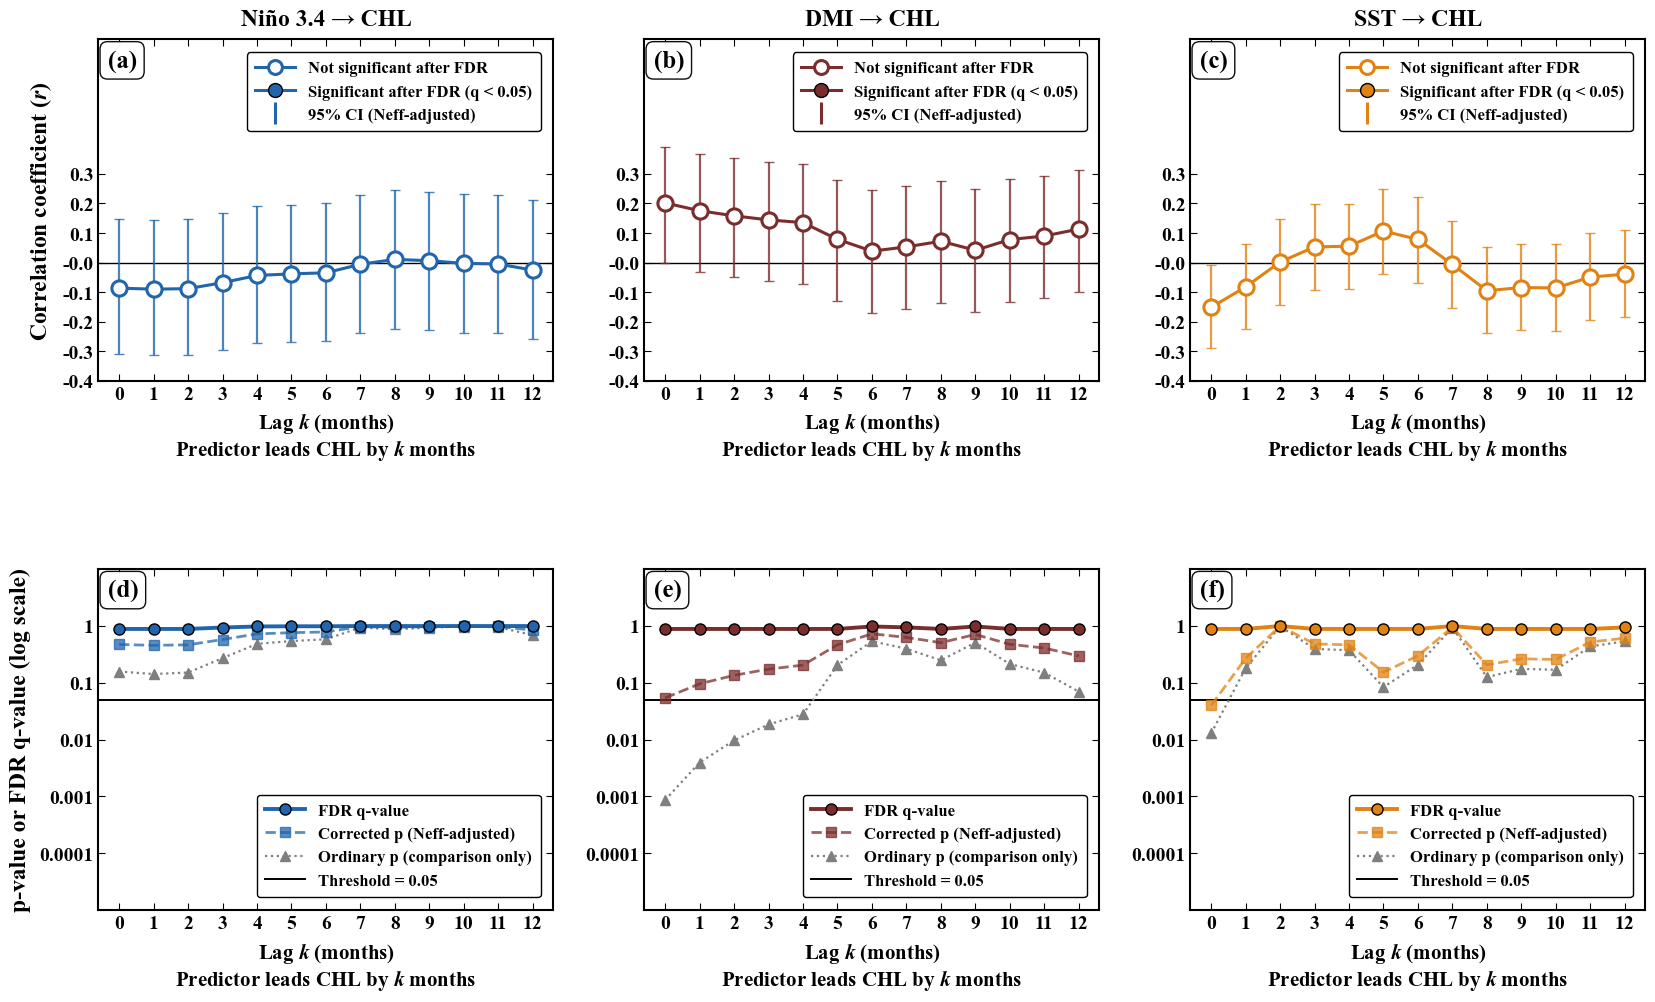

In [2]:
"""
Lag analysis figure
Reads sheet "Gap_Aware_Lag" and plots, for Niño 3.4, DMI and SST vs CHL:
  Top row    : r with 95% CI (Neff-adjusted), filled marker = significant after FDR
  Bottom row : FDR q-value, corrected p, ordinary p (log axis), line at 0.05
Lag k = predictor at (t - k) paired with CHL at t (predictor leads CHL by k months).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.ticker import FuncFormatter, NullLocator

# ─────────────────────────────────────────────
# USER INPUTS
# ─────────────────────────────────────────────
INPUT_FILE = "Gap_Aware_Lag_Analysis.xlsx"
SHEET      = "Gap_Aware_Lag"
OUT_FIG    = "Gap_Aware_Lag_Analysis.pdf"

ALPHA          = 0.05
HIGHLIGHT_LAGS = ()      # optional light vertical guides, for example (3, 12); empty = off
# ─────────────────────────────────────────────

# (name in the sheet, label on the figure, color)
PREDICTORS = [
    ("Nino34", "Niño 3.4", "#2166ac"),   # blue
    ("DMI",    "DMI",      "#7b2d2d"),   # maroon
    ("SST",    "SST",      "#e08214"),   # orange
]
C_GRAY = "#7f7f7f"

# ── Font sizes ────────────────────────────────
FS_BASE, FS_LABEL, FS_XLABEL = 16, 17, 15
FS_TITLE, FS_TICK, FS_LEG, FS_PANEL = 17, 14, 12, 18

# ── Load and check ───────────────────────────
df = pd.read_excel(INPUT_FILE, sheet_name=SHEET)
df.columns = df.columns.astype(str).str.strip()

needed = ["Predictor", "Response", "Lag_months", "N", "Neff", "r", "ordinary_p",
          "corrected_p", "CI95_low", "CI95_high", "FDR_q", "FDR_significant"]
missing = [c for c in needed if c not in df.columns]
if missing:
    raise KeyError(f"Missing columns in sheet '{SHEET}': {missing}\nFound: {list(df.columns)}")

df = df[df["Response"].astype(str).str.strip().str.upper() == "CHL"].copy()
df["Predictor"] = df["Predictor"].astype(str).str.strip()
for c in ["Lag_months", "N", "Neff", "r", "ordinary_p", "corrected_p",
          "CI95_low", "CI95_high", "FDR_q"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["sig"] = df["FDR_significant"].astype(str).str.strip().str.upper().isin(["TRUE", "1", "1.0", "YES"])

found = sorted(df["Predictor"].unique())
for key, _, _ in PREDICTORS:
    if key not in found:
        raise KeyError(f"Predictor '{key}' not found. Names in the sheet: {found}")

# ── Common axis limits ───────────────────────
PMIN = 1e-6
for col in ["ordinary_p", "corrected_p", "FDR_q"]:
    df[col] = df[col].clip(lower=PMIN, upper=1.0)

r_lo, r_hi = df["CI95_low"].min(), df["CI95_high"].max()
r_span = r_hi - r_lo
R_YLIM = (r_lo - 0.06 * r_span, r_hi + 0.52 * r_span)      # blank band on top for legend
r_ticks = np.round(np.arange(np.floor(r_lo / 0.1) * 0.1, r_hi + 1e-9, 0.1), 2)

p_min_exp = np.floor(np.log10(df[["ordinary_p", "corrected_p", "FDR_q"]].min().min()))
P_TOP_PAD = 1.0   # decades of blank space ABOVE p = 1 (for the panel letter); raise it to push the curves lower
P_BOT_PAD = 1.0   # decades of blank space BELOW the smallest p (for the legend)
P_YLIM = (10 ** (p_min_exp - P_BOT_PAD), 10 ** P_TOP_PAD)
p_ticks = [10.0 ** e for e in range(int(p_min_exp), 1)]   # ticks stop at 1, so the blank band above has no tick

# ── Style ─────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": FS_BASE, "font.weight": "bold",
    "axes.labelsize": FS_LABEL, "axes.labelweight": "bold",
    "axes.titlesize": FS_TITLE, "axes.titleweight": "bold",
    "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK,
    "axes.linewidth": 1.5, "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 5, "ytick.major.size": 5,
    "mathtext.fontset": "custom", "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic", "mathtext.bf": "Times New Roman:bold",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
})

XLABEL = "Lag $k$ (months)\nPredictor leads CHL by $k$ months"

def style_legend(ax, handles, loc, anchor):
    ax.legend(handles=handles, loc=loc, bbox_to_anchor=anchor, ncol=1,
              fontsize=FS_LEG, frameon=True, framealpha=1.0, edgecolor="black",
              borderpad=0.5, handlelength=2.4, labelspacing=0.45)

def panel_letter(ax, text):
    ax.text(0.02, 0.97, text, transform=ax.transAxes, fontsize=FS_PANEL,
            fontweight="bold", va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor="black", linewidth=1.0, alpha=0.95))

# ── Figure ────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
plt.subplots_adjust(left=0.075, right=0.985, top=0.93, bottom=0.10,
                    wspace=0.20, hspace=0.55)
letters = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

for j, (key, label, color) in enumerate(PREDICTORS):
    s = df[df["Predictor"] == key].sort_values("Lag_months")
    k   = s["Lag_months"].values
    r   = s["r"].values
    lo, hi = s["CI95_low"].values, s["CI95_high"].values
    sig = s["sig"].values

    # ═══ Top row: r with 95% CI ═══
    ax = axes[0, j]
    for g in HIGHLIGHT_LAGS:
        ax.axvline(g, color="gray", linewidth=1.0, linestyle=":", zorder=0)
    ax.axhline(0, color="black", linewidth=1.0, zorder=1)
    ax.errorbar(k, r, yerr=[r - lo, hi - r], fmt="none", ecolor=color,
                elinewidth=1.6, capsize=3.5, alpha=0.8, zorder=2)
    ax.plot(k, r, color=color, linewidth=2.2, zorder=3)
    ax.scatter(k[sig], r[sig], s=120, color=color, edgecolors="black",
               linewidths=1.0, zorder=4)
    ax.scatter(k[~sig], r[~sig], s=120, facecolors="white", edgecolors=color,
               linewidths=2.2, zorder=4)

    ax.set_title(f"{label} → CHL", pad=10)
    ax.set_xticks(range(0, 13))
    ax.set_xlim(-0.6, 12.6)
    ax.set_ylim(*R_YLIM)
    ax.set_yticks(r_ticks)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}"))
    ax.set_xlabel(XLABEL, fontsize=FS_XLABEL, labelpad=6)
    if j == 0:
        ax.set_ylabel(r"Correlation coefficient ($\mathit{r}$)", labelpad=6)
    ax.tick_params(which="both", top=True, right=True)
    panel_letter(ax, letters[j])

    top_handles = [
        mlines.Line2D([], [], color=color, marker="o", markersize=10, linewidth=2.2,
                      markerfacecolor="white", markeredgecolor=color, markeredgewidth=2.2,
                      label="Not significant after FDR"),
        mlines.Line2D([], [], color=color, marker="o", markersize=10, linewidth=2.2,
                      markerfacecolor=color, markeredgecolor="black",
                      label="Significant after FDR (q < 0.05)"),
        mlines.Line2D([], [], color=color, marker="|", markersize=16, linestyle="",
                      markeredgewidth=2.2, label="95% CI (Neff-adjusted)"),
    ]
    style_legend(ax, top_handles, "upper right", (0.99, 0.985))

    # ═══ Bottom row: p-values, log axis ═══
    ax = axes[1, j]
    for g in HIGHLIGHT_LAGS:
        ax.axvline(g, color="gray", linewidth=1.0, linestyle=":", zorder=0)
    ax.axhline(ALPHA, color="black", linewidth=1.4, zorder=1)
    ax.plot(k, s["ordinary_p"].values, color=C_GRAY, linewidth=1.6, linestyle=":",
            marker="^", markersize=7, zorder=2)
    ax.plot(k, s["corrected_p"].values, color=color, linewidth=2.0, linestyle="--",
            marker="s", markersize=7, alpha=0.75, zorder=3)
    ax.plot(k, s["FDR_q"].values, color=color, linewidth=2.8, linestyle="-",
            marker="o", markersize=8, markeredgecolor="black", zorder=4)

    ax.set_yscale("log")
    ax.set_ylim(*P_YLIM)
    ax.set_yticks(p_ticks)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_xticks(range(0, 13))
    ax.set_xlim(-0.6, 12.6)
    ax.set_xlabel(XLABEL, fontsize=FS_XLABEL, labelpad=6)
    if j == 0:
        ax.set_ylabel("p-value or FDR q-value (log scale)", labelpad=6)
    ax.tick_params(which="both", top=True, right=True)
    panel_letter(ax, letters[3 + j])

    bottom_handles = [
        mlines.Line2D([], [], color=color, linewidth=2.8, linestyle="-", marker="o",
                      markersize=8, markeredgecolor="black", label="FDR q-value"),
        mlines.Line2D([], [], color=color, linewidth=2.0, linestyle="--", marker="s",
                      markersize=7, alpha=0.75, label="Corrected p (Neff-adjusted)"),
        mlines.Line2D([], [], color=C_GRAY, linewidth=1.6, linestyle=":", marker="^",
                      markersize=7, label="Ordinary p (comparison only)"),
        mlines.Line2D([], [], color="black", linewidth=1.4, label=f"Threshold = {ALPHA}"),
    ]
    style_legend(ax, bottom_handles, "lower right", (0.99, 0.015))

fig.savefig(OUT_FIG, format="pdf", bbox_inches="tight", facecolor="white")
print("Figure saved →", OUT_FIG)

# ── Console summary for the text, caption and supplement ──
print("\nSummary per predictor (lags 0-12)")
for key, label, _ in PREDICTORS:
    s = df[df["Predictor"] == key]
    pk = s.loc[s["r"].abs().idxmax()]
    print(f"\n{label} → CHL")
    print(f"  N: {int(s['N'].min())}-{int(s['N'].max())} | "
          f"Neff: {s['Neff'].min():.1f}-{s['Neff'].max():.1f}")
    print(f"  Largest |r| = {pk['r']:.3f} at lag {int(pk['Lag_months'])}")
    print(f"  Lags with ordinary p < {ALPHA}  : {int((s['ordinary_p'] < ALPHA).sum())}")
    print(f"  Lags with corrected p < {ALPHA} : {int((s['corrected_p'] < ALPHA).sum())}")
    print(f"  Lags with FDR q < {ALPHA}       : {int((s['FDR_q'] < ALPHA).sum())} "
          f"(smallest q = {s['FDR_q'].min():.3f})")

plt.show()